# Phase 3 — Clustering occupations by numeric attributes

**Pipeline:** O*NET attribute scores (abilities, knowledge, work activities, skills) → StandardScaler → K-Means++ vs. Ward agglomerative

Each row is an occupation, each column one attribute's **importance** score (1–5). 910 occupations × 161 attributes.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from numeric_clustering import *
pd.set_option("display.max_colwidth", 140)

F_im, F_lv = load_features("IM"), load_features("LV")
occ = pd.read_csv(PROCESSED / "occupations.csv", index_col="code")
interests = pd.read_csv(PROCESSED / "interests.csv", index_col="code")
titles = occ.loc[F_im.index, "title"]
reference = {"SOC": pd.Series(F_im.index.str[:2]),
             "RIASEC": interests.reindex(F_im.index)["top_interest"].fillna("NA").reset_index(drop=True)}
F_im.shape

(910, 161)

## 1. Which scale? Importance (IM) vs. Level (LV)
Each attribute has two scores. If they carry the same information, using both just double-counts.

In [2]:
r = np.corrcoef(F_im.values.ravel(), F_lv.values.ravel())[0, 1]
print(f"Correlation between IM and LV scores: {r:.3f}")

Correlation between IM and LV scores: 0.959


They are almost the same (r ≈ 0.96), so we use **importance only**.

## 2. Standardize
Attributes are on similar 1–5 scales but with very different spreads (e.g. *Oral Comprehension* is important for
almost every job; *Programming* for few). Z-scoring stops high-variance attributes from dominating the distances.

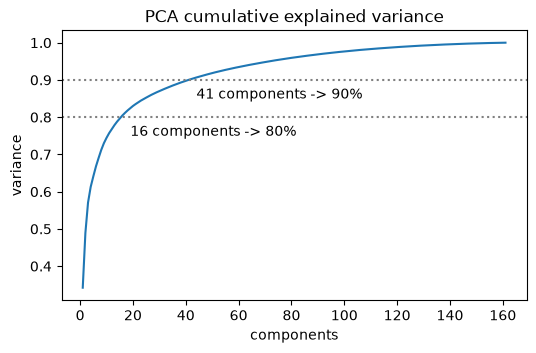

First component alone: 34%


In [3]:
Z = standardize(F_im)

pca = PCA().fit(Z)
cum = pca.explained_variance_ratio_.cumsum()
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(cum) + 1), cum)
for t in (0.8, 0.9):
    n = (cum < t).sum() + 1
    plt.axhline(t, ls=":", c="grey"); plt.text(n + 3, t - 0.05, f"{n} components -> {t:.0%}")
plt.title("PCA cumulative explained variance"); plt.xlabel("components"); plt.ylabel("variance"); plt.show()
print(f"First component alone: {cum[0]:.0%}")

The first principal component explains ~34% on its own: roughly a **physical ↔ cognitive/office** axis.
The rest of the variance is spread thinly, which means the job space is a **continuum**, not well-separated islands.

## 3. Choosing K: elbow + silhouette

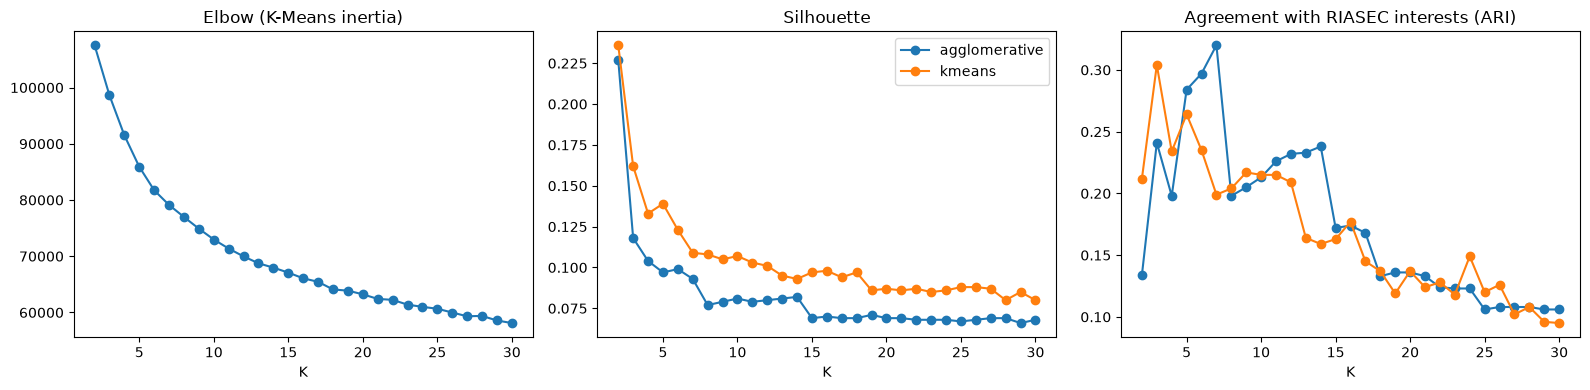

In [4]:
results = sweep(Z, ks=range(2, 31), reference=reference)
km_res = results[results.method == "kmeans"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(km_res.k, km_res.inertia, "o-"); ax[0].set(title="Elbow (K-Means inertia)", xlabel="K")
for m, g in results.groupby("method"):
    ax[1].plot(g.k, g.silhouette, "o-", label=m)
    ax[2].plot(g.k, g.ARI_vs_RIASEC, "o-", label=m)
ax[1].set(title="Silhouette", xlabel="K"); ax[2].set(title="Agreement with RIASEC interests (ARI)", xlabel="K")
ax[1].legend(); plt.tight_layout(); plt.show()

In [5]:
results[results.k.isin([2, 3, 4, 5, 6, 8, 10, 15, 20, 30])].round(3)

,method,k,inertia,n_clusters,noise_pct,silhouette,ARI_vs_SOC,ARI_vs_RIASEC
0,kmeans,2,107528.239,2,0.0,0.236,0.080,0.212
1,agglomerative,2,NaN,2,0.0,0.227,0.073,0.134
2,kmeans,3,98605.921,3,0.0,0.162,0.127,0.304
3,agglomerative,3,NaN,3,0.0,0.118,0.110,0.241
4,kmeans,4,91495.956,4,0.0,0.133,0.149,0.234
5,agglomerative,4,NaN,4,0.0,0.104,0.118,0.198
6,kmeans,5,85901.508,5,0.0,0.139,0.192,0.264
7,agglomerative,5,NaN,5,0.0,0.097,0.160,0.284
8,kmeans,6,81735.598,6,0.0,0.123,0.186,0.235
9,agglomerative,6,NaN,6,0.0,0.099,0.180,0.297


**Observations**
- Silhouette scores are **low (~0.07–0.24)** for every K: the numeric space has no sharp cluster boundaries.
  The math "optimum" is K=2 (physical vs. non-physical jobs), which is too coarse to be useful.
- The elbow is smooth, with no clear bend.
- K-Means beats Ward agglomerative on silhouette at almost every K.
- Agreement with **RIASEC interests peaks around K=3–6** (ARI ≈ 0.23–0.30), much higher than the text clusters (~0.10).

Silhouette alone can't settle it, so section 3b checks five methods and **chooses K automatically**.

## 3b. Choosing K automatically

Five standard methods, each run with K-Means++ for K = 2–30:

| Method | Picks the K where… |
|---|---|
| **Elbow (Kneedle)** | the inertia curve bends most: the point farthest from a straight line joining its two ends |
| **Silhouette** | jobs are closest to their own cluster relative to the next nearest (higher = better) |
| **Davies-Bouldin** | clusters are compact and far apart (lower = better) |
| **Calinski-Harabasz** | between-cluster spread is largest relative to within-cluster spread (higher = better) |
| **Gap statistic** | clustering beats random data with no structure by the most (Tibshirani's 1-standard-error rule) |

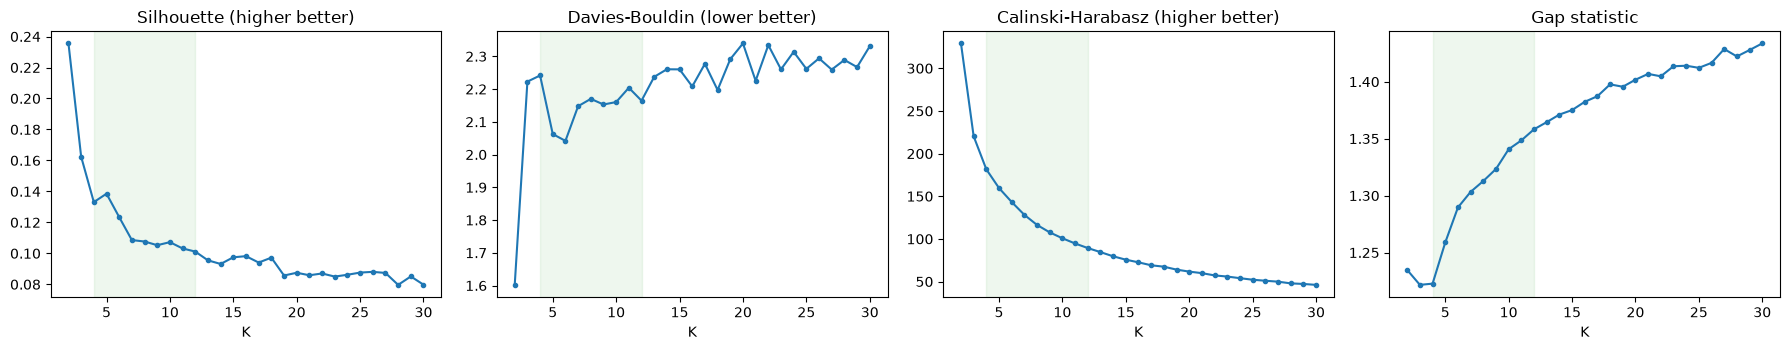

,best K (2-30)
Elbow (Kneedle),10
Silhouette,2
Davies-Bouldin,2
Calinski-Harabasz,2
Gap statistic,2


In [6]:
ks = range(2, 31)
metrics = k_metrics(Z, ks)
gap = gap_statistic(Z, ks, metrics["inertia"])
metrics = metrics.join(gap)

picks = pd.Series({
    "Elbow (Kneedle)": kneedle(ks, metrics["inertia"]),
    "Silhouette": int(metrics["silhouette"].idxmax()),
    "Davies-Bouldin": int(metrics["davies_bouldin"].idxmin()),
    "Calinski-Harabasz": int(metrics["calinski_harabasz"].idxmax()),
    "Gap statistic": gap_choice(gap),
}, name="best K (2-30)")

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, col, title in zip(ax, ["silhouette", "davies_bouldin", "calinski_harabasz", "gap"],
                         ["Silhouette (higher better)", "Davies-Bouldin (lower better)",
                          "Calinski-Harabasz (higher better)", "Gap statistic"]):
    a.plot(metrics.index, metrics[col], "o-", ms=3)
    a.axvspan(K_MIN, K_MAX, color="tab:green", alpha=0.08)
    a.set(title=title, xlabel="K")
plt.tight_layout(); plt.show()
picks.to_frame()

**Every internal metric's optimum is K=2**, and the gap statistic agrees. K=2 is a real result: the clearest split in
the data is physical vs. non-physical work (the first principal component). It's also very stable (see below).
But two groups are too coarse to explore careers, and the gap statistic keeps rising slowly with K, another sign
of a continuum rather than separate islands.

**Rule used to pick K automatically:** within a useful range of **4–12 groups** (shaded above: at least 4 broad
choices, at most 12 so they stay easy to scan), take the K with the **best average rank across silhouette,
Davies-Bouldin and Calinski-Harabasz**. The elbow is reported alongside but not voted, because inertia always falls
as K grows.

In [7]:
K_AUTO, avg_rank = choose_k(metrics)
table = metrics.loc[K_MIN:K_MAX, ["silhouette", "davies_bouldin", "calinski_harabasz", "gap"]].round(3)
table["average rank"] = avg_rank.round(2)
table["stability (bootstrap ARI)"] = [round(stability(Z, k), 3) for k in table.index]
print(f"Automatically chosen K = {K_AUTO}   (elbow suggests {picks['Elbow (Kneedle)']}; "
      f"stability of K=2 for reference: {stability(Z, 2):.2f})")
table.style.highlight_min(subset=["average rank"], color="#c8e6c9")

Automatically chosen K = 5   (elbow suggests 10; stability of K=2 for reference: 0.95)


,silhouette,davies_bouldin,calinski_harabasz,gap,average rank,stability (bootstrap ARI)
k,,,,,,
4,0.133000,2.242000,181.584000,1.223000,4.000000,0.810000
5,0.139000,2.063000,159.632000,1.259000,1.670000,0.732000
6,0.123000,2.042000,143.282000,1.290000,2.330000,0.728000
7,0.109000,2.148000,128.209000,1.303000,3.670000,0.581000
8,0.108000,2.170000,116.390000,1.313000,5.670000,0.538000
9,0.105000,2.153000,107.682000,1.323000,5.670000,0.607000
10,0.107000,2.160000,100.763000,1.341000,6.000000,0.574000
11,0.103000,2.204000,94.670000,1.348000,8.000000,0.590000
12,0.101000,2.165000,89.312000,1.358000,8.000000,0.550000


**Result: K=5** has the best average rank: it's first on silhouette within the range, and second on both
Davies-Bouldin (just behind K=6) and Calinski-Harabasz (just behind K=4). K=5 is chosen the same way whether the range is 4–10,
4–12 or 4–15. Bootstrap stability is moderate (~0.6) for every K from 4 to 8, so no K in this range is
clearly more stable than the others; only K=2 is (~0.96).

The rest of this notebook uses `K_AUTO`. An earlier version picked K=6 by hand; K=5 is nearly the same grouping,
with the "teaching & social" and "business & admin" groups merged into one communication-focused group.

## 4. Agglomerative (Ward) dendrogram

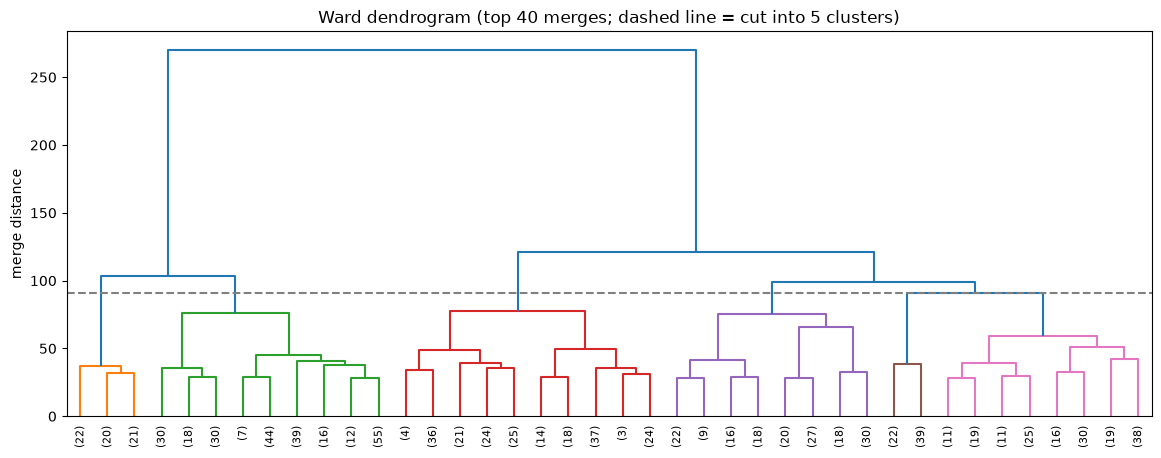

In [8]:
Lk = linkage(Z, method="ward")
cut = Lk[-K_AUTO, 2]
plt.figure(figsize=(14, 5))
dendrogram(Lk, truncate_mode="lastp", p=40, leaf_rotation=90, color_threshold=cut)
plt.axhline(cut, ls="--", c="grey")
plt.title(f"Ward dendrogram (top 40 merges; dashed line = cut into {K_AUTO} clusters)"); plt.ylabel("merge distance"); plt.show()

The tree is the main advantage of agglomerative clustering: it gives a **ready-made hierarchy**, which is
what the nested bubble UI needs. Cutting higher or lower gives coarser or finer levels.

## 5. The automatically chosen clusters: what defines them?

In [9]:
K = K_AUTO
km = run_kmeans(Z, K)
labels = km.labels_
ria = interests.reindex(F_im.index)["top_interest"]

summary = pd.DataFrame({
    "size": pd.Series(labels).value_counts().sort_index(),
    "defining_attributes": profile(Z, labels, n=5),
    "top_interest": [ria[labels == c].value_counts().index[0] for c in range(K)],
    "examples": [", ".join(titles[labels == c].sample(4, random_state=0)) for c in range(K)],
})
summary

,size,defining_attributes,top_interest,examples
0,181,"Assisting and Caring for Others, Medicine and Dentistry, Psychology, Therapy and Counseling, Service Orientation",Realistic,"Obstetricians and Gynecologists, Hydroelectric Production Managers, Podiatrists, Airfield Operations Specialists"
1,132,"Performing for or Working Directly with the Public, Trunk Strength, Food Production, Stamina, Dynamic Flexibility",Realistic,"Shipping, Receiving, and Inventory Clerks, Gambling Change Persons and Booth Cashiers, Bailiffs, Merchandise Displayers and Window Trimmers"
2,240,"Equipment Maintenance, Repairing, Repairing and Maintaining Mechanical Equipment, Reaction Time, Rate Control",Realistic,"Electrical Power-Line Installers and Repairers, Continuous Mining Machine Operators, Electricians, Rock Splitters, Quarry"
3,214,"Speech Clarity, Speaking, Active Listening, Writing, Oral Expression",Social,"First-Line Supervisors of Office and Administrative Support Workers, Logisticians, Mental Health and Substance Abuse Social Workers, Pre..."
4,143,"Programming, Engineering and Technology, Technology Design, Mathematical Reasoning, Mathematics",Investigative,"Architects, Except Landscape and Naval, Nuclear Monitoring Technicians, Computer Network Support Specialists, Computer Hardware Engineers"


The **defining attributes** (highest average z-score) work as an automatic label, much like TF-IDF on text:

| Cluster theme | Defining attributes |
|---|---|
| Tech & analysis | Programming, Engineering and Technology, Technology Design, Mathematics |
| Mechanical & repair | Equipment Maintenance, Repairing, Reaction Time, Rate Control |
| Communication & people | Speech Clarity, Speaking, Active Listening, Writing |
| Healthcare & caregiving | Assisting and Caring for Others, Medicine and Dentistry, Psychology, Therapy and Counseling |
| Physical & public-facing service | Working Directly with the Public, Trunk Strength, Food Production, Stamina |

(Cluster numbers are arbitrary; match them using the table above.)

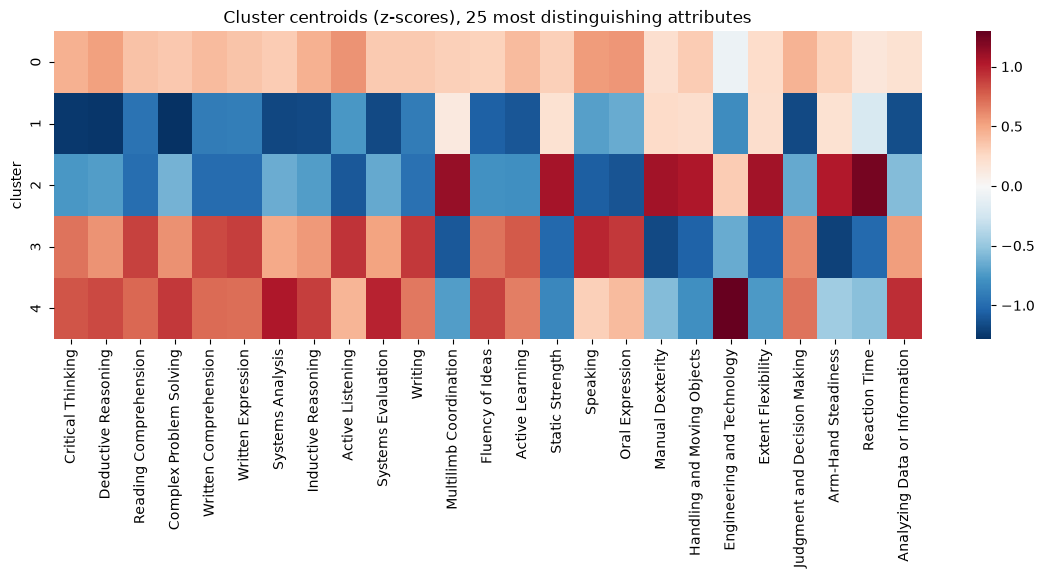

In [10]:
# Heatmap of cluster centroids on the attributes that vary most between clusters
centroids = Z.groupby(labels).mean()
top_attrs = centroids.std().sort_values(ascending=False).index[:25]
plt.figure(figsize=(14, 4))
sns.heatmap(centroids[top_attrs].rename(columns=lambda c: c.split(":", 1)[1]), cmap="RdBu_r", center=0)
plt.title("Cluster centroids (z-scores), 25 most distinguishing attributes"); plt.ylabel("cluster"); plt.show()

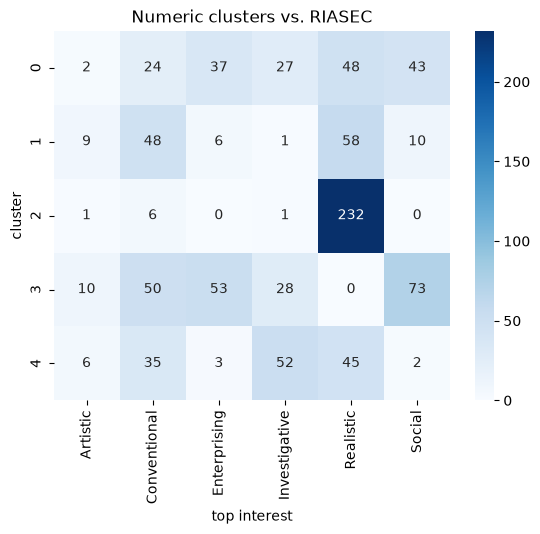

In [11]:
# Clusters vs. RIASEC interest type
ct = pd.crosstab(pd.Series(labels, index=F_im.index, name="cluster"), ria.rename("top interest"))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues"); plt.title("Numeric clusters vs. RIASEC"); plt.show()

## 6. Niche jobs (silhouette threshold)
K-Means puts every job in a cluster. Jobs with a **negative silhouette** are closer to another cluster than their own:
they don't fit well anywhere. These are flagged as niche, as the README suggests.

In [12]:
niche = misfits(Z, labels, threshold=0.0)
print(f"{niche.sum()} of {len(niche)} jobs ({niche.mean():.0%}) have negative silhouette")
titles[niche].sample(15, random_state=1).tolist()

41 of 910 jobs (5%) have negative silhouette


['Logistics Analysts',
 'Compliance Officers',
 'Meter Readers, Utilities',
 'Laborers and Freight, Stock, and Material Movers, Hand',
 'Cooks, Institution and Cafeteria',
 'Automotive Glass Installers and Repairers',
 'Motion Picture Projectionists',
 'Medical Appliance Technicians',
 'Coil Winders, Tapers, and Finishers',
 'Hotel, Motel, and Resort Desk Clerks',
 'Solar Sales Representatives and Assessors',
 'Shoe and Leather Workers and Repairers',
 'Floor Layers, Except Carpet, Wood, and Hard Tiles',
 'Gem and Diamond Workers',
 'Camera and Photographic Equipment Repairers']

## 7. 2D view

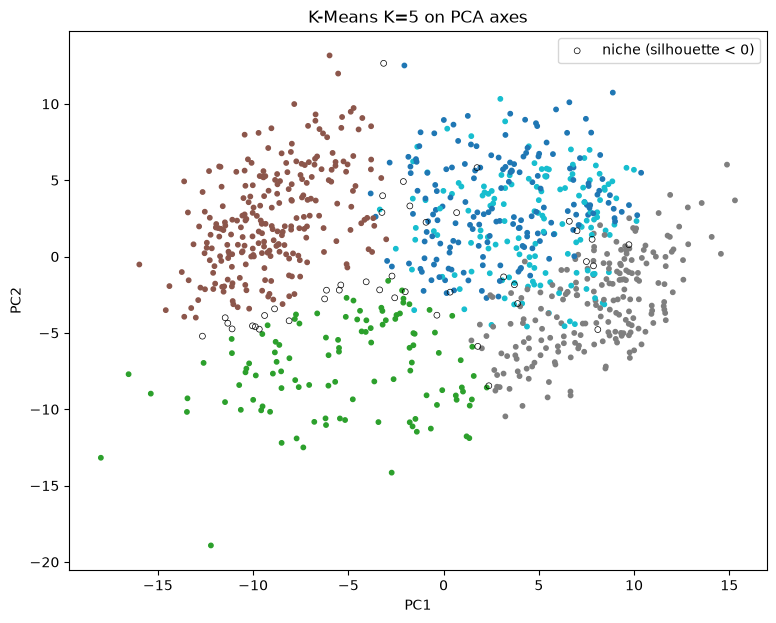

In [13]:
P2 = PCA(n_components=2).fit_transform(Z)
plt.figure(figsize=(9, 7))
plt.scatter(P2[~niche, 0], P2[~niche, 1], c=labels[~niche], cmap="tab10", s=10)
plt.scatter(P2[niche, 0], P2[niche, 1], facecolors="none", edgecolors="k", s=18, lw=0.5, label="niche (silhouette < 0)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title(f"K-Means K={K} on PCA axes"); plt.show()

## 8. Comparison with the text clusters (Project 1)
Uses `data/processed/text_clusters.csv` from Project 1's notebook; skipped if that file isn't present.

In [14]:
km30 = run_kmeans(Z, 30).labels_  # also saved at the end of the notebook
text_path = PROCESSED / "text_clusters.csv"
if not text_path.exists():
    print("Skipped: run Project 1 (notebooks/02_text_clustering.ipynb) first to compare with the text clusters.")
else:
    text = pd.read_csv(text_path, index_col="code").loc[F_im.index]
    lab = pd.Series(labels, index=F_im.index)
    print(f"ARI numeric K={K}  vs text K-Means K=30:", round(adjusted_rand_score(lab, text.kmeans), 3))
    print("ARI numeric K=30 vs text K-Means K=30:", round(adjusted_rand_score(km30, text.kmeans), 3))

    # How do the text clusters spread across the numeric groups?
    mask = text.hdbscan.values != -1
    ct = pd.crosstab(text.hdbscan[mask], lab[mask])
    purity = ct.max(axis=1) / ct.sum(axis=1)
    print(f"On average, {purity.mean():.0%} of a text cluster's jobs fall in the same numeric group")

ARI numeric K=5  vs text K-Means K=30: 0.113
ARI numeric K=30 vs text K-Means K=30: 0.233
On average, 70% of a text cluster's jobs fall in the same numeric group


## 9. Findings

| | Text clusters (Project 1) | Numeric clusters (Project 2) |
|---|---|---|
| What they capture | **what** the job is about (field / domain) | **how** the job is done (physical, social, analytical…) |
| Cluster separation | clear (silhouette ~0.60 after UMAP) | weak (silhouette ~0.07–0.24), a continuum |
| Number of clusters | ~30 (found by HDBSCAN) | **5, chosen automatically** (consensus of three metrics within 4–12) |
| Matches RIASEC interests | poorly (ARI ~0.10) | better (ARI ~0.26 at K=5) |

- **Choosing K:** every internal metric's global optimum is K=2 (physical vs. non-physical work): the strongest,
  most stable split, but too coarse to explore careers. Within a useful 4–12 range, the consensus of silhouette,
  Davies-Bouldin and Calinski-Harabasz picks **K=5**, robustly across range choices. The elbow (Kneedle) suggests 10.
- The README expected numeric data to cluster "remarkably well". In practice it doesn't separate cleanly,
  because jobs change gradually from physical to cognitive work. The clusters are still **meaningful and easy to name**:
  tech & analysis, mechanical & repair, communication & people, healthcare & caregiving, physical & public-facing service.
- K-Means++ beats Ward agglomerative on silhouette, but Ward gives a **tree**, which helps build a hierarchy.
- **41 jobs (5%)** have a negative silhouette and are flagged as niche.
- The two projects capture **different things** and agree only partly (ARI ~0.11), so they complement each other:
  on average 70% of a text cluster's jobs fall in a single numeric group.

**How this fed the bubble UI:** numeric groups describe *how* work is done and match career interests better, while text
clusters keep fields together. The final top level combines ideas from both: 9 named groups assigned by task meaning
(see `notebooks/06_top_groups.ipynb`), with text-based subclusters inside each.

In [15]:
out = pd.DataFrame({"title": titles, "kmeans_auto": labels, "kmeans6": run_kmeans(Z, 6).labels_,
                    "kmeans30": km30, "agglo_auto": run_agglomerative(Z, K), "niche": niche,
                    "pca_x": P2[:, 0], "pca_y": P2[:, 1]}, index=F_im.index)
out.to_csv(PROCESSED / "numeric_clusters.csv")
summary[["size", "defining_attributes", "top_interest"]].to_csv(PROCESSED / "numeric_cluster_profiles.csv")
print(f"Saved K={K} labels (kmeans_auto) plus the earlier hand-picked K=6 (kmeans6) for notebooks 04-05")
out.head()

Saved K=5 labels (kmeans_auto) plus the earlier hand-picked K=6 (kmeans6) for notebooks 04-05


,title,kmeans_auto,kmeans6,kmeans30,agglo_auto,niche,pca_x,pca_y
code,,,,,,,,
11-1011.00,Chief Executives,3,2,3,4,False,14.877012,6.020195
11-1011.03,Chief Sustainability Officers,3,2,3,0,False,11.759110,1.372922
11-1021.00,General and Operations Managers,3,2,3,4,False,7.881747,1.505883
11-2011.00,Advertising and Promotions Managers,3,2,3,4,False,9.235859,-1.532468
11-2021.00,Marketing Managers,3,2,3,4,False,10.408225,-0.090452
